# VALE3 RNN (estudo)

Carrega `vale3_1y.csv`, corta no tempo, depois a rede (NumPy). Não é recomendação de trade.

In [11]:
from pathlib import Path
import csv

HERE = Path("/Users/italo/apps/Leetcodes/vale3")
CSV = HERE / "vale3_1y.csv"
rows = list(csv.DictReader(CSV.open()))
labeled = [r for r in rows if r["label"] != ""]
len(rows), len(labeled), str(CSV)

(247, 246, '/Users/italo/apps/Leetcodes/vale3/vale3_1y.csv')

In [12]:
cut = int(0.8 * len(labeled))
train, test = labeled[:cut], labeled[cut:]
len(train), len(test), train[0]["date"], test[0]["date"]

(196, 50, '2025-10-20', '2026-08-05')

## Rede

Janelas de tamanho N e o `forward` da RNN entram aqui.

In [13]:
N = 10

def windows(rows, n):
    xs, ys = [], []
    for i in range(n - 1, len(rows)):
        xs.append(rows[i - n + 1 : i + 1])
        ys.append(int(rows[i]["label"]))
    return xs, ys

x_train, y_train = windows(train, N)
x_test, y_test = windows(test, N)
len(x_train), len(x_test)

(187, 41)

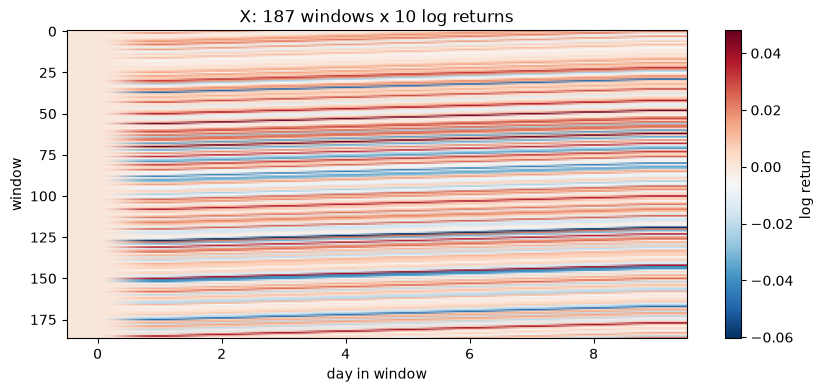

In [14]:
import math
import numpy as np

def features(window):
    xs = [0.0]
    for i in range(1, len(window)):
        prev = float(window[i - 1]["close"])
        cur = float(window[i]["close"])
        xs.append(math.log(cur) - math.log(prev))
    return np.array(xs)

X = np.array([features(w) for w in x_train])
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4)); plt.imshow(X, aspect='auto', cmap='RdBu_r'); plt.colorbar(label='log return'); plt.xlabel('day in window'); plt.ylabel('window'); plt.title('X: 187 windows x 10 log returns'); plt.show()


In [15]:
# forward RNN (PDF): h_t = tanh(W_xh x_t + W_hh h_{t-1} + b_h), y = W_hy h_10 + b_y
# hidden size 1; pesos do exemplo do PDF — sem treino
W_xh, W_hh, b_h = 1.0, 0.5, 0.1
W_hy, b_y = 1.0, 0.0

def sigmoid(z):
    return 1 / (1 + math.exp(-z))

def rnn_forward(x_row):
    h = 0.0  # h_0
    for xt in x_row:  # t = 1..10
        h = math.tanh(W_xh * xt + W_hh * h + b_h)  # h_t
    y = sigmoid(W_hy * h + b_y)
    return h, y

hs, ys = [], []
for row in X:
    h10, y = rnn_forward(row)
    hs.append(h10)
    ys.append(y)
hs, ys = np.array(hs), np.array(ys)

print("hs.shape", hs.shape, "ys.shape", ys.shape)
for i in range(5):
    print(i, hs[i], ys[i])


hs.shape (187,) ys.shape (187,)
0 0.22462418448320293 0.5559211138556857
1 0.21043210630672485 0.5524147514408563
2 0.19149547057295768 0.5477281055210032
3 0.20956128404336674 0.5521994284758129
4 0.19853500544715524 0.5494713604717151


In [16]:
# BCE: y_train já é 0/1 (label do último dia da janela = next_close > close)
y_true = np.array(y_train, dtype=float)
y_pred = np.clip(ys, 1e-7, 1 - 1e-7)
bce = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
print("BCE", bce)
print("ys > 0.5", int((ys > 0.5).sum()), "ys <= 0.5", int((ys <= 0.5).sum()))


BCE 0.6882007970498422
ys > 0.5 187 ys <= 0.5 0


In [17]:
# treino: BPTT, h escalar, SGD na BCE (PDF § Treino)
X_test = np.array([features(w) for w in x_test])
y_true = np.array(y_train, dtype=float)
y_test_arr = np.array(y_test, dtype=float)

def clip01(p):
    return float(np.clip(p, 1e-7, 1 - 1e-7))

def forward_cache(x_row):
    h = 0.0
    hs, xs = [h], []
    for xt in x_row:
        xt = float(xt)
        z = W_xh * xt + W_hh * h + b_h
        h = math.tanh(z)
        xs.append(xt)
        hs.append(h)
    logit = W_hy * h + b_y
    y = 1 / (1 + math.exp(-max(-30.0, min(30.0, logit))))
    return clip01(y), hs, xs

def bce_one(y, t):
    return -(t * math.log(y) + (1 - t) * math.log(1 - y))

def backward(y, t, hs, xs):
    # dL/dlogit = y - t  (BCE + sigmoid)
    dlogit = y - t
    g_W_hy = dlogit * hs[-1]
    g_b_y = dlogit
    dh = dlogit * W_hy
    g_W_xh = g_W_hh = g_b_h = 0.0
    for t_step in range(len(xs) - 1, -1, -1):
        h_t = hs[t_step + 1]
        h_prev = hs[t_step]
        xt = xs[t_step]
        dz = dh * (1 - h_t * h_t)
        g_W_xh += dz * xt
        g_W_hh += dz * h_prev
        g_b_h += dz
        dh = dz * W_hh
    return g_W_xh, g_W_hh, g_b_h, g_W_hy, g_b_y

def mean_bce(X, labels):
    return float(np.mean([bce_one(forward_cache(row)[0], t) for row, t in zip(X, labels)]))

lr = 0.5
epochs = 200
clip = 5.0
for ep in range(1, epochs + 1):
    g = np.zeros(5)
    for row, t in zip(X, y_true):
        y, hs, xs = forward_cache(row)
        grads = backward(y, t, hs, xs)
        g += np.array(grads)
    g /= len(X)
    g = np.clip(g, -clip, clip)
    W_xh -= lr * g[0]
    W_hh -= lr * g[1]
    b_h -= lr * g[2]
    W_hy -= lr * g[3]
    b_y -= lr * g[4]
    if ep == 1 or ep % 50 == 0 or ep == epochs:
        print(f"ep {ep:3d}  train BCE {mean_bce(X, y_true):.5f}  "
              f"W=({W_xh:.3f},{W_hh:.3f},{b_h:.3f},{W_hy:.3f},{b_y:.3f})")


ep   1  train BCE 0.68819  W=(1.000,0.500,0.102,1.000,0.001)
ep  50  train BCE 0.68818  W=(0.994,0.483,0.109,0.993,-0.001)
ep 100  train BCE 0.68816  W=(0.988,0.465,0.115,0.987,-0.004)
ep 150  train BCE 0.68814  W=(0.982,0.448,0.122,0.981,-0.007)
ep 200  train BCE 0.68812  W=(0.977,0.430,0.128,0.975,-0.009)


In [18]:
# teste: acurácia + matriz 2x2 vs baselines (experimento.tex)
def predict(X_rows):
    return np.array([forward_cache(row)[0] for row in X_rows])

def acc_and_cm(pred, labels):
    hat = (pred >= 0.5).astype(int)
    lab = labels.astype(int)
    acc = float((hat == lab).mean())
    tn = int(((hat == 0) & (lab == 0)).sum())
    fp = int(((hat == 1) & (lab == 0)).sum())
    fn = int(((hat == 0) & (lab == 1)).sum())
    tp = int(((hat == 1) & (lab == 1)).sum())
    return acc, np.array([[tn, fp], [fn, tp]])

ys_tr = predict(X)
ys_te = predict(X_test)
maj = 1 if y_true.mean() >= 0.5 else 0
base_maj = np.full(len(y_test_arr), maj, dtype=float)
# "sobe se o último retorno da janela foi > 0"
base_mom = (X_test[:, -1] > 0).astype(float)

print("train BCE", mean_bce(X, y_true), "test BCE", mean_bce(X_test, y_test_arr))
for name, pred, lab in [
    ("RNN train", ys_tr, y_true),
    ("RNN test", ys_te, y_test_arr),
    ("baseline maioria (treino) no teste", base_maj, y_test_arr),
    ("baseline mom. (último retorno > 0) no teste", base_mom, y_test_arr),
]:
    acc, cm = acc_and_cm(pred, lab)
    print(f"{name}: acc={acc:.3f}  [[tn fp][fn tp]]={cm.tolist()}")
print("pesos finais", W_xh, W_hh, b_h, W_hy, b_y)


train BCE 0.688123569691349 test BCE 0.7051424565038575
RNN train: acc=0.551  [[tn fp][fn tp]]=[[0, 84], [0, 103]]
RNN test: acc=0.463  [[tn fp][fn tp]]=[[0, 22], [0, 19]]
baseline maioria (treino) no teste: acc=0.463  [[tn fp][fn tp]]=[[0, 22], [0, 19]]
baseline mom. (último retorno > 0) no teste: acc=0.585  [[tn fp][fn tp]]=[[13, 9], [8, 11]]
pesos finais 0.977270251259439 0.42952564320903647 0.12765582070330836 0.9752884077923977 -0.009244227566787035
